<a href="https://colab.research.google.com/github/purinpurin11/Micas-blancas/blob/EL-ORGANAL/El_organal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sube el archivo MICAS Y RT.xlsx


Saving MICAS Y RT.xlsx to MICAS Y RT.xlsx
Dimensiones del archivo: (69, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,Mica blanca,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Rutilo,NaN
1,Muestra,No.,Código de muestra,Si,Al,Fe,Mg,NaN,NaN,Muestra,Zr
2,1,4,25CA035-Z1-Wm-1,3.3,2.2002,0.2619,0.2514,NaN,NaN,1,354



Pares mica-rutilo: 47
Outliers Zr (>1000 ppm) eliminados: 1
Rutilo huérfano (sin mica): 19
Distribución de pares por Muestra:
grupo
1    29
2    18
Name: count, dtype: int64


### Outliers de Zr eliminados (>1000 ppm)

,No,codigo,grupo,Si,Zr
17,21.0,25CA035-Z1-Wm-18,1,3.3159,1500.0


... (4 outputs left out)

## Resumen por Muestra (1 / 2)

,grupo,n,P_mediana_GPa,P_p16,P_p84,T_mediana_C,T_p16,T_p84
0,1,29.0,2.218,2.160,2.262,700.036,688.799,705.430
1,2,18.0,2.150,2.093,2.179,702.866,687.981,708.401


## Resumen por grupo de fengita

,grupo_fengita,n,P_mediana_GPa,P_p16,P_p84,T_mediana_C,T_p16,T_p84
0,G2: Si≥3.25,47.0,2.187,2.137,2.237,701.684,687.49,706.337


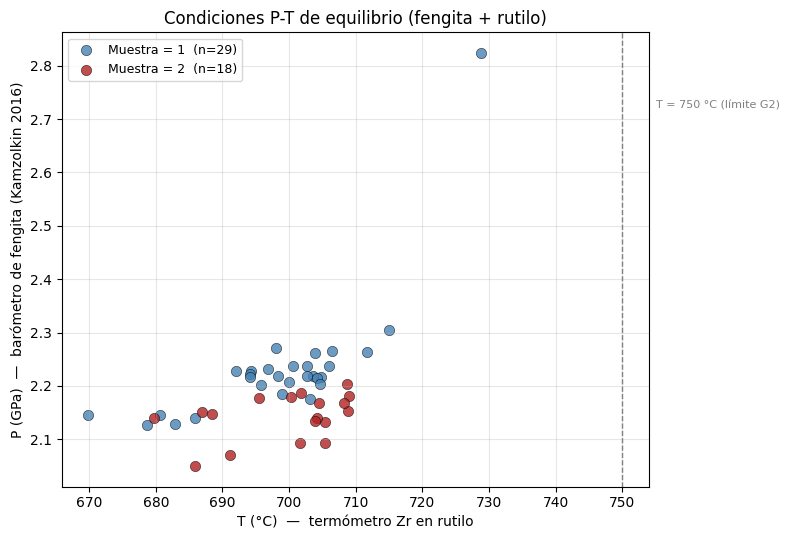

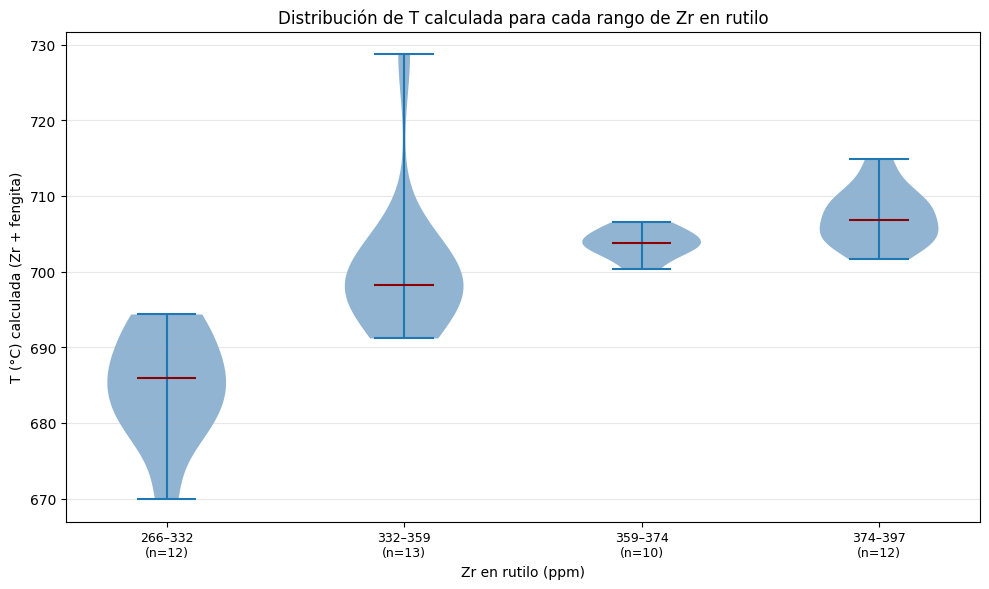


Excel generado: MICAS_RT_resultados.xlsx
Hojas: Resumen_PT, Proceso_iterativo, Resumen_Muestra, Resumen_Fengita, Outliers_Zr, Rutilo_sin_pareja


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# Cálculo P-T: fengita (Kamzolkin et al. 2016) + Zr en rutilo
# Archivo: MICAS Y RT.xlsx
# Google Colab
# ============================================================

!pip -q install openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. Subir y leer Excel
# ------------------------------------------------------------
print("Sube el archivo MICAS Y RT.xlsx")
uploaded = files.upload()
path = next(iter(uploaded))

SHEET = "Mica y rutilo"
ZR_MAX_PPM = 1000       # Zr > 1000 ppm = inclusión de circón → descartar

raw = pd.read_excel(path, sheet_name=SHEET, header=None)
print(f"Dimensiones del archivo: {raw.shape}")
display(raw.head(3))

# fila 0: títulos | fila 1: headers | fila 2+: datos
df = raw.iloc[2:].copy().reset_index(drop=True)
df.columns = ["mica_muestra", "No", "codigo", "Si", "Al", "Fe", "Mg",
              "c8", "c9", "rt_muestra", "Zr"]

for col in ["Si", "Al", "Fe", "Mg", "Zr", "No"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Limpiar '=1' / '=2' -> 1 / 2
def clean_grupo(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lstrip("=").strip()
    try:
        return int(float(s))
    except ValueError:
        return np.nan

df["grupo"] = (df["mica_muestra"].apply(clean_grupo)
               .combine_first(df["rt_muestra"].apply(clean_grupo)))
df["grupo"] = df["grupo"].fillna(-1).astype(int)

# Quitar filas totalmente vacías
df = df[~(df["Si"].isna() & df["Zr"].isna())].reset_index(drop=True)

# ------------------------------------------------------------
# 2. Emparejar mica-rutilo por fila (mismo No. de muestra)
# ------------------------------------------------------------
pairs_all = df.dropna(subset=["Si", "Al", "Fe", "Mg", "Zr"]).copy()
pairs_all = pairs_all[pairs_all["Zr"] > 0].reset_index(drop=True)
pairs_all["MgFe"] = pairs_all["Mg"] + pairs_all["Fe"]

# Outliers de Zr
outliers = pairs_all[pairs_all["Zr"] > ZR_MAX_PPM].copy()
pairs   = pairs_all[pairs_all["Zr"] <= ZR_MAX_PPM].copy().reset_index(drop=True)

# Rutilo huérfano (solo Zr, sin mica)
rut_solo = df[df["Zr"].notna() & df["Si"].isna()].copy()
rut_solo = rut_solo[rut_solo["Zr"] > 0].reset_index(drop=True)

print(f"\n{'='*60}")
print(f"Pares mica-rutilo: {len(pairs)}")
print(f"Outliers Zr (>{ZR_MAX_PPM} ppm) eliminados: {len(outliers)}")
print(f"Rutilo huérfano (sin mica): {len(rut_solo)}")
print(f"Distribución de pares por Muestra:")
print(pairs["grupo"].value_counts().sort_index())
print(f"{'='*60}")

if len(outliers) > 0:
    display(Markdown("### Outliers de Zr eliminados (>1000 ppm)"))
    display(outliers[["No", "codigo", "grupo", "Si", "Zr"]])

# ------------------------------------------------------------
# 3. Fórmulas
# ------------------------------------------------------------
R = 8.31447  # J/(mol·K)

def P_fengita(T_C, Si, Al, MgFe):
    """Kamzolkin et al. (2016). G1 = ec. (4), G2 = ec. (5)."""
    if Si < 3.25:
        num = 0.023 * T_C + 5.99 * Si + 1.76 * Al + 12.89 * MgFe - 31.91
        return num / 10.0, num, "G1: Si<3.25 (ec. 4)"
    else:
        num = 0.030 * T_C + 19.21 * Si - 2.91 * Al + 2.17 * MgFe - 57.22
        return num / 10.0, num, "G2: Si≥3.25 (ec. 5)"

def T_rutilo(P_GPa, C_ppm):
    """T(°C) por Zr en rutilo (P en bar, C en ppm)."""
    P_bar = P_GPa * 10000.0
    num = 71360.0 + 0.378 * P_bar - 0.130 * C_ppm
    den = 130.66 - R * np.log(C_ppm)
    return num / den - 273.1, num, den, P_bar

def solve_PT(Si, Al, MgFe, Zr_ppm, P0=1.0, T0=600.0,
             max_iter=50, tol_P=1e-8, tol_T=1e-4):
    P, T = P0, T0
    pasos = []
    for it in range(1, max_iter + 1):
        T_new, numT, denT, Pbar = T_rutilo(P, Zr_ppm)
        P_new, numP, eq = P_fengita(T_new, Si, Al, MgFe)
        pasos.append({
            "iter": it, "P_in (GPa)": P, "P_bar": Pbar,
            "T_calc (°C)": T_new, "num_T": numT, "den_T": denT,
            "P_calc (GPa)": P_new, "num_P": numP, "eq": eq,
            "ΔT (°C)": abs(T_new - T), "ΔP (GPa)": abs(P_new - P),
        })
        if abs(T_new - T) < tol_T and abs(P_new - P) < tol_P:
            return P_new, T_new, pasos
        P, T = P_new, T_new
    return P, T, pasos

# ------------------------------------------------------------
# 4. Calcular P-T de cada par
# ------------------------------------------------------------
P_list, T_list, grupo_f_list, iter_list = [], [], [], []
procesos = {}

for idx, row in pairs.iterrows():
    P, T, pasos = solve_PT(row["Si"], row["Al"], row["MgFe"], row["Zr"])
    P_list.append(P); T_list.append(T)
    grupo_f_list.append("G1: Si<3.25" if row["Si"] < 3.25 else "G2: Si≥3.25")
    iter_list.append(len(pasos))
    procesos[idx] = pasos

pairs["P_GPa"] = P_list
pairs["T_C"]   = T_list
pairs["grupo_fengita"] = grupo_f_list
pairs["n_iter"] = iter_list
pairs["G2_valida"] = ~((pairs["Si"] >= 3.25) & (pairs["T_C"] >= 750))

assert (pairs["P_GPa"] > 0).all(), "Presiones no positivas. Revisar datos."
print(f"\nRango P: {pairs['P_GPa'].min():.2f} – {pairs['P_GPa'].max():.2f} GPa")
print(f"Rango T: {pairs['T_C'].min():.1f} – {pairs['T_C'].max():.1f} °C")
print(f"Iteraciones: {pairs['n_iter'].min()} – {pairs['n_iter'].max()}")
print(f"Pares inválidos (G2 & T≥750): {(~pairs['G2_valida']).sum()}")

# ------------------------------------------------------------
# 5. Tabla completa de resultados
# ------------------------------------------------------------
tabla = pairs[["No", "codigo", "grupo", "grupo_fengita",
               "Si", "Al", "Fe", "Mg", "MgFe", "Zr",
               "n_iter", "P_GPa", "T_C", "G2_valida"]].copy()
tabla.columns = ["No.", "Código", "Muestra", "Grupo fengita",
                 "Si", "Al", "Fe", "Mg", "Mg+Fe", "Zr (ppm)",
                 "iter", "P (GPa)", "T (°C)", "G2 válido"]

display(Markdown("## Tabla completa de pares mica–rutilo"))
display(tabla.round(4))

# ------------------------------------------------------------
# 6. Proceso iterativo completo
# ------------------------------------------------------------
filas = []
for idx, pasos_i in procesos.items():
    row = pairs.loc[idx]
    for p in pasos_i:
        filas.append({
            "No.": row["No"], "Código": row["codigo"],
            "Muestra": row["grupo"], "Si": row["Si"],
            "Grupo": row["grupo_fengita"], "Zr (ppm)": row["Zr"],
            "iter": p["iter"],
            "P_in (GPa)": p["P_in (GPa)"],
            "P_bar": p["P_bar"],
            "T_calc (°C)": p["T_calc (°C)"],
            "P_calc (GPa)": p["P_calc (GPa)"],
            "Ecuación": p["eq"],
            "ΔT (°C)": p["ΔT (°C)"],
            "ΔP (GPa)": p["ΔP (GPa)"],
        })
proceso_df = pd.DataFrame(filas)

# ------------------------------------------------------------
# 7. Resúmenes
# ------------------------------------------------------------
def resumen(g):
    return pd.Series({
        "n": len(g),
        "P_mediana_GPa": g["P_GPa"].median(),
        "P_p16": g["P_GPa"].quantile(0.16),
        "P_p84": g["P_GPa"].quantile(0.84),
        "T_mediana_C":   g["T_C"].median(),
        "T_p16":         g["T_C"].quantile(0.16),
        "T_p84":         g["T_C"].quantile(0.84),
    })

resumen_muestra = pairs.groupby("grupo").apply(resumen).reset_index()
resumen_fengita = pairs.groupby("grupo_fengita").apply(resumen).reset_index()

display(Markdown("## Resumen por Muestra (1 / 2)"))
display(resumen_muestra.round(3))
display(Markdown("## Resumen por grupo de fengita"))
display(resumen_fengita.round(3))

# ------------------------------------------------------------
# 8. Gráfico P-T (scatter por Muestra)
# ------------------------------------------------------------
fig_pt, ax = plt.subplots(figsize=(8, 5.5))
colores = {1: "steelblue", 2: "firebrick"}
for g, sub in pairs.groupby("grupo"):
    ax.scatter(sub["T_C"], sub["P_GPa"], s=55, alpha=0.8,
               edgecolor="k", linewidth=0.4,
               color=colores.get(g, "gray"),
               label=f"Muestra = {g}  (n={len(sub)})")
ax.axvline(750, ls="--", c="gray", lw=1)
ax.text(755, ax.get_ylim()[1] * 0.95, "T = 750 °C (límite G2)",
        fontsize=8, color="gray")
ax.set_xlabel("T (°C)  —  termómetro Zr en rutilo")
ax.set_ylabel("P (GPa)  —  barómetro de fengita (Kamzolkin 2016)")
ax.set_title("Condiciones P-T de equilibrio (fengita + rutilo)")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="best")
plt.tight_layout()
plt.show()
fig_pt.savefig("scatter_PT.png", dpi=150, bbox_inches="tight")

# ------------------------------------------------------------
# 9. Diagrama de violín: Zr (ppm) vs T (°C)
# ------------------------------------------------------------
# bins adaptativos por cuantiles (grupos de igual tamaño)
n_bins = 4
try:
    zr_cat, zr_edges = pd.qcut(pairs["Zr"], q=n_bins, retbins=True,
                               duplicates="drop", labels=False)
    pairs["Zr_bin"] = zr_cat
except Exception:
    zr_edges = np.linspace(pairs["Zr"].min(),
                           pairs["Zr"].max() + 1, n_bins + 1)
    pairs["Zr_bin"] = pd.cut(pairs["Zr"], bins=zr_edges,
                             labels=False, include_lowest=True)

zr_labels_disp = [f"{zr_edges[i]:.0f}–{zr_edges[i+1]:.0f}"
                  for i in range(len(zr_edges) - 1)]

fig_v, ax_v = plt.subplots(figsize=(10, 6))
data_v, pos_v, lab_v = [], [], []
for b in range(len(zr_labels_disp)):
    vals = pairs.loc[pairs["Zr_bin"] == b, "T_C"].dropna().values
    if len(vals) >= 2:
        data_v.append(vals)
        pos_v.append(b + 1)
        lab_v.append(f"{zr_labels_disp[b]}\n(n={len(vals)})")

vp = ax_v.violinplot(data_v, positions=pos_v,
                     showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("steelblue")
    body.set_alpha(0.6)
vp["cmedians"].set_color("darkred")

ax_v.set_xticks(pos_v)
ax_v.set_xticklabels(lab_v, fontsize=9)
ax_v.set_xlabel("Zr en rutilo (ppm)")
ax_v.set_ylabel("T (°C) calculada (Zr + fengita)")
ax_v.set_title("Distribución de T calculada para cada rango de Zr en rutilo")
ax_v.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()
fig_v.savefig("violin_T_vs_Zr.png", dpi=150, bbox_inches="tight")

# ------------------------------------------------------------
# 10. Exportar Excel con varias hojas + imágenes
# ------------------------------------------------------------
XLSX = "MICAS_RT_resultados.xlsx"

with pd.ExcelWriter(XLSX, engine="openpyxl") as writer:
    tabla.round(4).to_excel(writer, sheet_name="Resumen_PT", index=False)
    proceso_df.round(5).to_excel(writer, sheet_name="Proceso_iterativo",
                                 index=False)
    resumen_muestra.round(3).to_excel(writer, sheet_name="Resumen_Muestra",
                                       index=False)
    resumen_fengita.round(3).to_excel(writer, sheet_name="Resumen_Fengita",
                                       index=False)
    outliers.to_excel(writer, sheet_name="Outliers_Zr", index=False)
    rut_solo.to_excel(writer, sheet_name="Rutilo_sin_pareja", index=False)

    from openpyxl.drawing.image import Image as XLImage
    ws = writer.sheets["Resumen_PT"]
    nrows = len(tabla) + 3
    ws.add_image(XLImage("scatter_PT.png"),     f"A{nrows}")
    ws.add_image(XLImage("violin_T_vs_Zr.png"), f"P{nrows}")

print(f"\nExcel generado: {XLSX}")
print("Hojas: Resumen_PT, Proceso_iterativo, Resumen_Muestra, "
      "Resumen_Fengita, Outliers_Zr, Rutilo_sin_pareja")

files.download(XLSX)

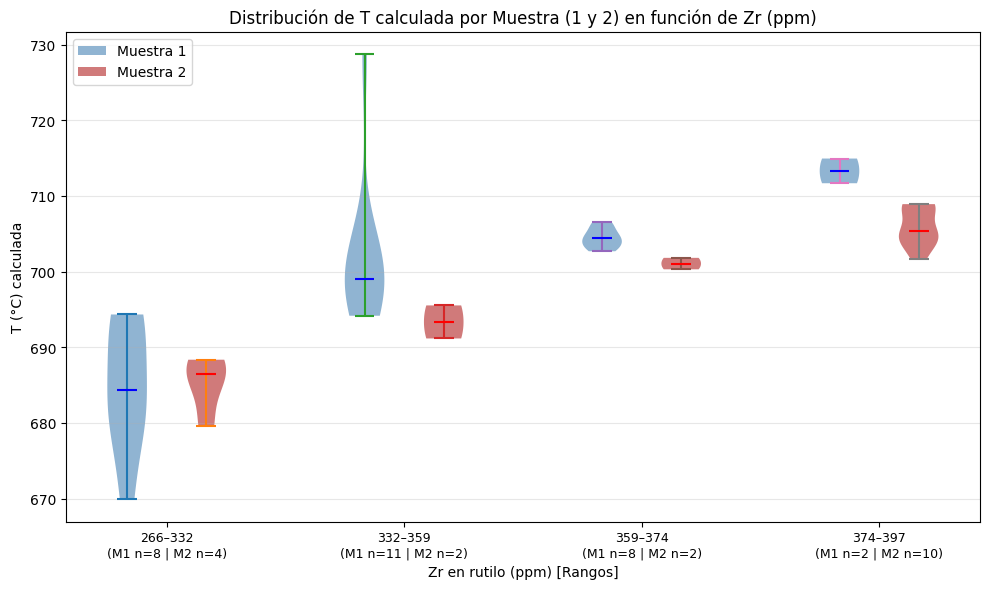


Nuevo archivo Excel generado con éxito: MICAS_RT_Muestras1y2_resultados.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown

# 1. Crear bins de Zr para Muestras 1 y 2 combinadas
pairs_m12 = pairs[pairs['grupo'].isin([1, 2])].copy()

n_bins_m12 = 4
try:
    zr_cat_m12, zr_edges_m12 = pd.qcut(pairs_m12['Zr'], q=n_bins_m12, retbins=True, duplicates='drop', labels=False)
    pairs_m12['Zr_bin'] = zr_cat_m12
except Exception:
    zr_edges_m12 = np.linspace(pairs_m12['Zr'].min(), pairs_m12['Zr'].max() + 1, n_bins_m12 + 1)
    pairs_m12['Zr_bin'] = pd.cut(pairs_m12['Zr'], bins=zr_edges_m12, labels=False, include_lowest=True)

zr_labels_m12 = [f"{zr_edges_m12[i]:.0f}–{zr_edges_m12[i+1]:.0f}" for i in range(len(zr_edges_m12) - 1)]

# 2. Graficar diagrama de violín para Muestra 1 vs Muestra 2
fig_v_m12, ax_v_m12 = plt.subplots(figsize=(10, 6))

# Preparar datos agrupados por bin de Zr y Muestra
posiciones = []
etiquetas = []
colores_v = {1: 'steelblue', 2: 'firebrick'}

# Iterar sobre cada bin de Zr
for b in range(len(zr_labels_m12)):
    # Para Muestra 1
    vals_m1 = pairs_m12[(pairs_m12['Zr_bin'] == b) & (pairs_m12['grupo'] == 1)]['T_C'].dropna().values
    # Para Muestra 2
    vals_m2 = pairs_m12[(pairs_m12['Zr_bin'] == b) & (pairs_m12['grupo'] == 2)]['T_C'].dropna().values

    pos_m1 = b * 3 + 1
    pos_m2 = b * 3 + 2

    if len(vals_m1) >= 2:
        vp1 = ax_v_m12.violinplot(vals_m1, positions=[pos_m1], showmedians=True, showextrema=True)
        for body in vp1['bodies']:
            body.set_facecolor(colores_v[1])
            body.set_alpha(0.6)
        vp1['cmedians'].set_color('blue')

    if len(vals_m2) >= 2:
        vp2 = ax_v_m12.violinplot(vals_m2, positions=[pos_m2], showmedians=True, showextrema=True)
        for body in vp2['bodies']:
            body.set_facecolor(colores_v[2])
            body.set_alpha(0.6)
        vp2['cmedians'].set_color('red')

    posiciones.append(b * 3 + 1.5)
    etiquetas.append(f"{zr_labels_m12[b]}\n(M1 n={len(vals_m1)} | M2 n={len(vals_m2)})")

ax_v_m12.set_xticks(posiciones)
ax_v_m12.set_xticklabels(etiquetas, fontsize=9)
ax_v_m12.set_xlabel("Zr en rutilo (ppm) [Rangos]")
ax_v_m12.set_ylabel("T (°C) calculada")
ax_v_m12.set_title("Distribución de T calculada por Muestra (1 y 2) en función de Zr (ppm)")
ax_v_m12.grid(alpha=0.3, axis='y')

# Añadir leyenda manual
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colores_v[1], alpha=0.6, label='Muestra 1'),
    Patch(facecolor=colores_v[2], alpha=0.6, label='Muestra 2')
]
ax_v_m12.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()
fig_v_m12.savefig("violin_T_vs_Zr_M12.png", dpi=150, bbox_inches="tight")

# 3. Exportar el nuevo Excel incluyendo el gráfico personalizado
XLSX_NUEVO = "MICAS_RT_Muestras1y2_resultados.xlsx"
with pd.ExcelWriter(XLSX_NUEVO, engine="openpyxl") as writer:
    tabla.round(4).to_excel(writer, sheet_name="Resumen_PT", index=False)
    proceso_df.round(5).to_excel(writer, sheet_name="Proceso_iterativo", index=False)
    resumen_muestra.round(3).to_excel(writer, sheet_name="Resumen_Muestra", index=False)
    resumen_fengita.round(3).to_excel(writer, sheet_name="Resumen_Fengita", index=False)
    outliers.to_excel(writer, sheet_name="Outliers_Zr", index=False)
    rut_solo.to_excel(writer, sheet_name="Rutilo_sin_pareja", index=False)

    from openpyxl.drawing.image import Image as XLImage
    ws = writer.sheets["Resumen_PT"]
    nrows = len(tabla) + 3
    ws.add_image(XLImage("scatter_PT.png"), f"A{nrows}")
    ws.add_image(XLImage("violin_T_vs_Zr_M12.png"), f"P{nrows}")

print(f"\nNuevo archivo Excel generado con éxito: {XLSX_NUEVO}")
files.download(XLSX_NUEVO)
